## Step 1: Select a dataset
- **Dataset name:** Diamonds dataset (prices and attributes of diamonds)
- **Source link:** https://raw.githubusercontent.com/mwaskom/seaborn-data/master/diamonds.csv (seaborn-data repository on GitHub; it is the well-known `diamonds` dataset from the R ggplot2 package, also available on Kaggle)
- **Domain:** Business / retail pricing
- **File type:** CSV
- **Why this dataset:** It is a medium-to-large dataset (about 54,000 rows), has both numerical and categorical columns, and contains hidden data-quality problems (invalid zero values, impossible outliers, duplicate rows) that are good for demonstrating cleaning.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', None)

## Step 2: Load and inspect the dataset

In [2]:
df_original = pd.read_csv('diamonds.csv')      # original data, kept untouched
print('Rows:', df_original.shape[0])
print('Columns:', df_original.shape[1])
print('File type: CSV')

Rows: 53940
Columns: 10
File type: CSV


In [3]:
print('First 5 rows')
display(df_original.head())
print('Last 5 rows')
display(df_original.tail())

First 5 rows


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


Last 5 rows


,carat,cut,color,clarity,depth,table,price,x,y,z
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74
53939,0.75,Ideal,D,SI2,62.2,55.0,2757,5.83,5.87,3.64


In [4]:
print('Column names:', list(df_original.columns))
print()
df_original.info()

Column names: ['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y', 'z']

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  str    
 2   color    53940 non-null  str    
 3   clarity  53940 non-null  str    
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), str(3)
memory usage: 4.1 MB


**What the dataset represents:** Each row is one diamond, with its physical measurements, quality grades and selling price.

| Column | Meaning |
|---|---|
| carat | Weight of the diamond |
| cut | Cut quality (Fair, Good, Very Good, Premium, Ideal) |
| color | Colour grade from D (best) to J (worst) |
| clarity | How clear the diamond is: I1 (worst), SI2, SI1, VS2, VS1, VVS2, VVS1, IF (best) |
| depth | Total depth percentage = z / mean(x, y) |
| table | Width of the top of the diamond relative to its widest point |
| price | Price in US dollars |
| x, y, z | Length, width and depth in mm |

## Step 3: Identify data types and basic statistics

In [5]:
numerical_cols = df_original.select_dtypes(include='number').columns.tolist()
categorical_cols = df_original.select_dtypes(exclude='number').columns.tolist()
print('Numerical columns  :', numerical_cols)
print('Categorical columns:', categorical_cols)

Numerical columns  : ['carat', 'depth', 'table', 'price', 'x', 'y', 'z']
Categorical columns: ['cut', 'color', 'clarity']


In [6]:
df_original.describe().round(2)

,carat,depth,table,price,x,y,z
count,53940.00,53940.00,53940.00,53940.00,53940.00,53940.00,53940.00
mean,0.80,61.75,57.46,3932.80,5.73,5.73,3.54
std,0.47,1.43,2.23,3989.44,1.12,1.14,0.71
min,0.20,43.00,43.00,326.00,0.00,0.00,0.00
25%,0.40,61.00,56.00,950.00,4.71,4.72,2.91
50%,0.70,61.80,57.00,2401.00,5.70,5.71,3.53
75%,1.04,62.50,59.00,5324.25,6.54,6.54,4.04
max,5.01,79.00,95.00,18823.00,10.74,58.90,31.80


In [7]:
# Suspicious values: dimensions of exactly 0 are not possible for a real diamond
print('Rows with zero in x, y or z:')
print((df_original[['x', 'y', 'z']] == 0).sum())
print()
print('Largest values of x, y, z:')
print(df_original[['x', 'y', 'z']].max())

Rows with zero in x, y or z:
x     8
y     7
z    20
dtype: int64

Largest values of x, y, z:
x    10.74
y    58.90
z    31.80
dtype: float64


In [8]:
# Rows with extremely large y or z values - checking them against their carat weight
df_original[(df_original['y'] > 12) | (df_original['z'] > 8)]

,carat,cut,color,clarity,depth,table,price,x,y,z
24067,2.00,Premium,H,SI2,58.9,57.0,12210,8.09,58.90,8.06
48410,0.51,Very Good,E,VS1,61.8,54.7,1970,5.12,5.15,31.80
49189,0.51,Ideal,E,VS1,61.8,55.0,2075,5.15,31.80,5.12


**Observations**
- **Possible target column for a future task:** `price` (continuous numerical value). No model is trained here.
- **Invalid values:** `x`, `y` and `z` contain zeros (8, 7 and 20 rows respectively). A diamond cannot have a size of 0 mm, so these zeros are really missing values stored as 0.
- **Impossible outliers:** three rows have `y` = 58.9 mm, `y` = 31.8 mm or `z` = 31.8 mm, while their carat weights (0.51 to 2.00) correspond to stones of roughly 5 to 8 mm. These look like data-entry errors, because the other two dimensions in the same row are normal.
- **No useful identifier:** the dataset has no ID column, so nothing needs to be dropped as an identifier.

## Step 4: Identify missing values

In [9]:
missing = pd.DataFrame({
    'missing_count': df_original.isnull().sum(),
    'missing_percent': (df_original.isnull().sum() / len(df_original) * 100).round(3)
})
missing

,missing_count,missing_percent
carat,0,0.0
cut,0,0.0
color,0,0.0
clarity,0,0.0
depth,0,0.0
table,0,0.0
price,0,0.0
x,0,0.0
y,0,0.0
z,0,0.0


Pandas reports **no** missing values in any column, so all 10 columns look complete. However, from Step 3 we know that zeros in `x`, `y`, `z` and a few impossible values are hiding as "valid" numbers. So the dataset has hidden missing values, and I convert them to proper missing values (`NaN`) in the next step so they can be counted and handled.

## Step 5: Handle missing values
First a copy of the original is made, then the hidden missing values are marked as `NaN`.

In [10]:
df = df_original.copy()      # working copy, original stays unchanged

# 1) zeros in x, y, z are invalid -> NaN
for col in ['x', 'y', 'z']:
    df.loc[df[col] == 0, col] = np.nan

# 2) three impossible outliers identified in Step 3 -> NaN
df.loc[df['y'] > 20, 'y'] = np.nan
df.loc[df['z'] > 20, 'z'] = np.nan

before = pd.DataFrame({
    'missing_count': df.isnull().sum(),
    'missing_percent': (df.isnull().sum() / len(df) * 100).round(3)
})
before[before.missing_count > 0]

,missing_count,missing_percent
x,8,0.015
y,9,0.017
z,21,0.039


In [11]:
# Fill using the median of each column
for col in ['x', 'y', 'z']:
    df[col] = df[col].fillna(df[col].median())

print('Missing values after handling:')
print(df.isnull().sum())

Missing values after handling:
carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64


**Why median imputation:** Only 23 rows (about 0.04%) were affected, so deleting them would also be acceptable, but there is a better reason to keep them: the other columns of these rows (carat, price, etc.) are valid and useful. The median is used instead of the mean because the dimensions are right-skewed and the mean is pulled by large values. Mode is not used because these are numerical columns, and forward/backward fill is not meaningful because the rows are not in any time order. No column was dropped.

## Step 6: Check duplicate records and consistency

In [12]:
dup_count = df.duplicated().sum()
print('Duplicate rows:', dup_count)
df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(10)

Duplicate rows: 146


,carat,cut,color,clarity,depth,table,price,x,y,z
43995,0.3,Good,J,VS1,63.4,57.0,394,4.23,4.26,2.69
47296,0.3,Good,J,VS1,63.4,57.0,394,4.23,4.26,2.69
34408,0.3,Ideal,G,IF,62.1,55.0,863,4.32,4.35,2.69
34422,0.3,Ideal,G,IF,62.1,55.0,863,4.32,4.35,2.69
28592,0.3,Ideal,G,VS2,63.0,55.0,675,4.31,4.29,2.71
28593,0.3,Ideal,G,VS2,63.0,55.0,675,4.31,4.29,2.71
31624,0.3,Ideal,H,SI1,62.2,57.0,450,4.26,4.29,2.66
31627,0.3,Ideal,H,SI1,62.2,57.0,450,4.26,4.29,2.66
31626,0.3,Ideal,H,SI1,62.2,57.0,450,4.27,4.28,2.66
31629,0.3,Ideal,H,SI1,62.2,57.0,450,4.27,4.28,2.66


In [13]:
df = df.drop_duplicates().reset_index(drop=True)
print('Duplicates remaining:', df.duplicated().sum())
print('Shape after removing duplicates:', df.shape)

Duplicates remaining:

 0
Shape after removing duplicates: (53794, 10)


In [14]:
# Consistency check for category labels: spelling, extra spaces, letter case
for col in ['cut', 'color', 'clarity']:
    print(col, '->', sorted(df[col].unique()))
    print('   labels with extra spaces :', (df[col] != df[col].str.strip()).sum())

cut -> ['Fair', 'Good', 'Ideal', 'Premium', 'Very Good']
   labels with extra spaces : 0
color -> ['D', 'E', 'F', 'G', 'H', 'I', 'J']
   labels with extra spaces : 0
clarity -> ['I1', 'IF', 'SI1', 'SI2', 'VS1', 'VS2', 'VVS1', 'VVS2']
   labels with extra spaces : 0


The labels are spelled consistently, with no extra spaces or mixed letter case, so no label correction was needed.

## Step 7: Basic EDA

In [15]:
print('Summary statistics of numerical columns')
display(df.describe().round(2))
print()
print('Frequency count of cut')
print(df['cut'].value_counts())
print()
print('Frequency count of color')
print(df['color'].value_counts())

Summary statistics of numerical columns


,carat,depth,table,price,x,y,z
count,53794.00,53794.00,53794.00,53794.00,53794.00,53794.00,53794.00
mean,0.80,61.75,57.46,3933.07,5.73,5.73,3.54
std,0.47,1.43,2.23,3988.11,1.12,1.11,0.69
min,0.20,43.00,43.00,326.00,3.73,3.68,1.07
25%,0.40,61.00,56.00,951.00,4.71,4.72,2.91
50%,0.70,61.80,57.00,2401.00,5.70,5.71,3.53
75%,1.04,62.50,59.00,5326.75,6.54,6.54,4.03
max,5.01,79.00,95.00,18823.00,10.74,10.54,8.06



Frequency count of cut
cut
Ideal        21488
Premium      13748
Very Good    12069
Good          4891
Fair          1598
Name: count, dtype: int64

Frequency count of color
color
G    11262
E     9776
F     9520
H     8272
D     6755
I     5407
J     2802
Name: count, dtype: int64


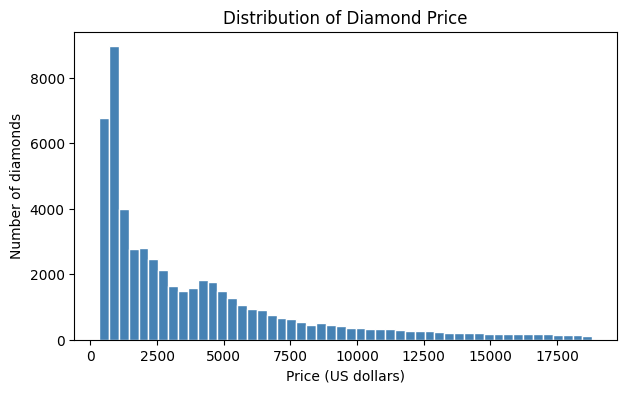

In [16]:
plt.figure(figsize=(7, 4))
plt.hist(df['price'], bins=50, color='steelblue', edgecolor='white')
plt.title('Distribution of Diamond Price')
plt.xlabel('Price (US dollars)')
plt.ylabel('Number of diamonds')
plt.show()

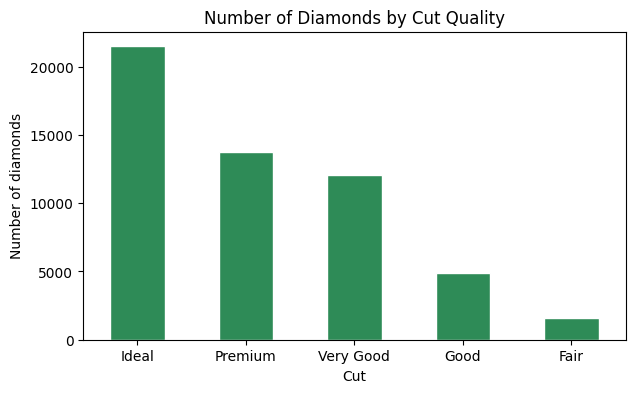

In [17]:
plt.figure(figsize=(7, 4))
df['cut'].value_counts().plot(kind='bar', color='seagreen', edgecolor='white')
plt.title('Number of Diamonds by Cut Quality')
plt.xlabel('Cut')
plt.ylabel('Number of diamonds')
plt.xticks(rotation=0)
plt.show()

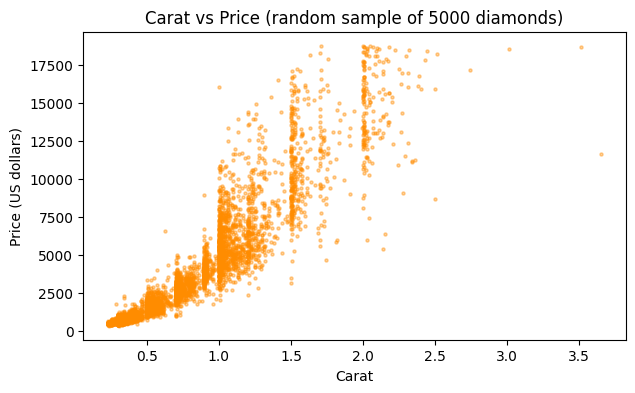

In [18]:
plt.figure(figsize=(7, 4))
sample = df.sample(5000, random_state=42)       # sample only to keep the plot readable
plt.scatter(sample['carat'], sample['price'], s=5, alpha=0.4, color='darkorange')
plt.title('Carat vs Price (random sample of 5000 diamonds)')
plt.xlabel('Carat')
plt.ylabel('Price (US dollars)')
plt.show()

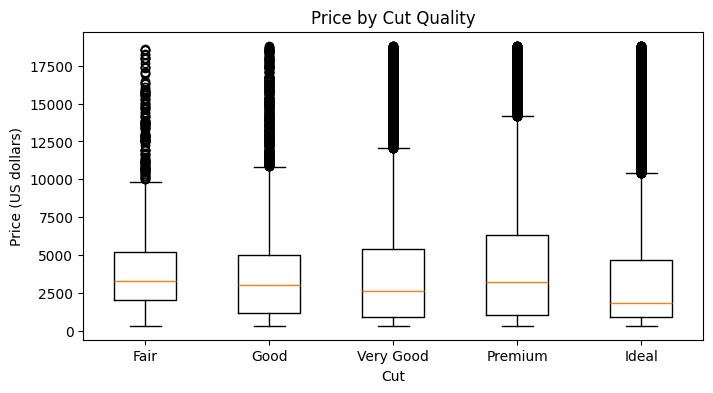

In [19]:
cut_order = ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal']
plt.figure(figsize=(8, 4))
plt.boxplot([df.loc[df['cut'] == c, 'price'] for c in cut_order])
plt.xticks(range(1, 6), cut_order)
plt.title('Price by Cut Quality')
plt.xlabel('Cut')
plt.ylabel('Price (US dollars)')
plt.show()

**Observations**
1. The price distribution is strongly right-skewed: most diamonds are cheap (a few thousand dollars) and only a small number are very expensive. Because of this, the mean price is higher than the median.
2. Price increases clearly with carat, and the spread of prices also grows for larger diamonds. The relationship is positive but not perfectly straight.
3. "Ideal" is the most common cut and "Fair" the least common, so the cut classes are imbalanced. Surprisingly, "Ideal" diamonds have the lowest median price in the box plot, because carat weight, which affects price much more, differs across cuts. This shows that a single column cannot explain price alone.

## Step 8: Encode categorical features


In [20]:
print('Before encoding:')
display(df[['cut', 'color', 'clarity']].head())

cut_map = {'Fair': 0, 'Good': 1, 'Very Good': 2, 'Premium': 3, 'Ideal': 4}
color_map = {'J': 0, 'I': 1, 'H': 2, 'G': 3, 'F': 4, 'E': 5, 'D': 6}                      # J worst ... D best
clarity_map = {'I1': 0, 'SI2': 1, 'SI1': 2, 'VS2': 3, 'VS1': 4, 'VVS2': 5, 'VVS1': 6, 'IF': 7}  # I1 worst ... IF best

df_encoded = df.copy()
df_encoded['cut'] = df_encoded['cut'].map(cut_map)
df_encoded['color'] = df_encoded['color'].map(color_map)
df_encoded['clarity'] = df_encoded['clarity'].map(clarity_map)

print('After encoding:')
display(df_encoded[['cut', 'color', 'clarity']].head())
print('Missing values created by mapping:', df_encoded[['cut', 'color', 'clarity']].isnull().sum().sum())

Before encoding:


,cut,color,clarity
0,Ideal,E,SI2
1,Premium,E,SI1
2,Good,E,VS1
3,Premium,I,VS2
4,Good,J,SI2


After encoding:


,cut,color,clarity
0,4,5,1
1,3,5,2
2,1,5,4
3,3,1,3
4,1,0,1


Missing values created by mapping: 0


## Step 9: Scale numerical features


In [21]:
scale_cols = ['carat', 'depth', 'table', 'x', 'y', 'z']

print('Before scaling (min and max):')
display(df_encoded[scale_cols].agg(['min', 'max']).round(2))

train_idx, test_idx = train_test_split(df_encoded.index, test_size=0.2, random_state=42)
print('Train rows:', len(train_idx), '| Test rows:', len(test_idx))

scaler = StandardScaler()
scaler.fit(df_encoded.loc[train_idx, scale_cols])      # learn from training data only

df_prepared = df_encoded.copy()
df_prepared[scale_cols] = scaler.transform(df_encoded[scale_cols])
df_prepared['split'] = 'train'
df_prepared.loc[test_idx, 'split'] = 'test'

print()
print('After scaling (training rows) - mean and std should be about 0 and 1:')
display(df_prepared.loc[train_idx, scale_cols].agg(['mean', 'std']).round(3))

Before scaling (min and max):


,carat,depth,table,x,y,z
min,0.20,43.0,43.0,3.73,3.68,1.07
max,5.01,79.0,95.0,10.74,10.54,8.06


Train rows: 43035 | Test rows: 10759

After scaling (training rows) - mean and std should be about 0 and 1:


,carat,depth,table,x,y,z
mean,-0.0,0.0,0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


## Step 10: Save the prepared dataset

In [22]:
print('Final shape:', df_prepared.shape)
print('Remaining missing values:', df_prepared.isnull().sum().sum())
print('Remaining duplicate rows:', df_prepared.drop(columns='split').duplicated().sum())
print()
print('Data types:')
print(df_prepared.dtypes)

Final shape: (53794, 11)
Remaining missing values: 0
Remaining duplicate rows: 0

Data types:
carat      float64
cut          int64
color        int64
clarity      int64
depth      float64
table      float64
price        int64
x          float64
y          float64
z          float64
split          str
dtype: object


In [23]:
df_prepared.to_csv('diamonds_prepared.csv', index=False)
print('Saved as: diamonds_prepared.csv')
display(pd.read_csv('diamonds_prepared.csv').head())

Saved as: diamonds_prepared.csv


,carat,cut,color,clarity,depth,table,price,x,y,z,split
0,-1.195566,4,5,1,-0.174423,-1.101291,326,-1.588086,-1.574515,-1.600404,train
1,-1.237584,3,5,2,-1.366120,1.585932,326,-1.641508,-1.700094,-1.773342,train
2,-1.195566,1,5,4,-3.399015,3.377413,327,-1.499049,-1.493785,-1.773342,train
3,-1.069512,3,1,3,0.456476,0.242320,334,-1.365494,-1.350267,-1.312174,train
4,-1.027493,1,0,1,1.087374,0.242320,335,-1.240842,-1.242628,-1.139236,test


In [24]:
# Check that the original file is unchanged
print('Original file shape (unchanged):', pd.read_csv('diamonds.csv').shape)

Original file shape (unchanged): (53940, 10)


## Conclusion
**Dataset:** The diamonds dataset (53,940 rows, 10 columns) was selected from seaborn-data/GitHub. It has 7 numerical and 3 categorical columns, and `price` can be used as a target in a future prediction task.

**Problems found:**
- No missing values were shown by pandas, but 35 zero values were hidden in `x`, `y`, `z` (mostly in `z`), and 3 impossible outliers (58.9 mm and 31.8 mm) were present.
- 146 exact duplicate rows.
- The price distribution is heavily right-skewed, and the cut classes are imbalanced.
- Category labels were already consistent.

**Preparation decisions:**
- Invalid zeros and impossible outliers were converted to missing values and filled with the column median, so valid information in other columns was kept.
- Duplicate rows were removed (53,794 rows remained) because there was no ID column to justify keeping them.
- `cut`, `color` and `clarity` were ordinal-encoded in their natural quality order.
- `carat`, `depth`, `table`, `x`, `y`, `z` were standardised, with the scaler fitted on training rows only to avoid data leakage; `price` was left unscaled.

**Output:** the prepared dataset was saved as `diamonds_prepared.csv` with no missing values and no duplicates, while the original `diamonds.csv` remains unchanged.

